# Week 2: Function 3 kernel comparison

Compare Gaussian-process kernels for Function 3 using the supplied observations. The notebook evaluates Matérn 3/2, Matérn 5/2, RBF, and Rational Quadratic covariance functions.

It visualizes fitted signal-kernel correlations and kernel-matrix similarity, plots posterior means and uncertainty on three pairwise 2D slices, and evaluates predictive performance on shared cross-validation folds. These are model comparisons on the observed domain, not evidence of a global optimum.

In [1]:
from itertools import combinations
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import (
    ConstantKernel,
    Matern,
    RBF,
    RationalQuadratic,
    WhiteKernel,
)
from sklearn.model_selection import KFold

from bayesian_bbo import CONFIG, load_observations
from bayesian_bbo.validation import cross_validate_kernels

FUNCTION_ID = 3
N_SPLITS = 5
LENGTH_CAP = 31.622776601683793
plt.style.use("seaborn-v0_8-whitegrid")

## 1. Set up the Function 3 environment

Function 3 has three continuous input coordinates and one scalar output. The repository stores inputs in the common `[0, 1)` domain, so this notebook leaves their scale intact; target normalization, optimizer restarts, and random seed use the shared settings in `config.yaml`.

## 2. Load data and define kernel candidates

Use the cumulative observations when available, otherwise the loader falls back to the initial `.npy` arrays. Matérn and RBF candidates use ARD length scales (one learned scale per coordinate). Scikit-learn's Rational Quadratic kernel has a single shared length scale, so it is isotropic here. All candidate kernels constrain their length scales to `[1e-3, LENGTH_CAP]`, where `LENGTH_CAP` is `31.62` for this run.

In [2]:
WEEK = 2  # read observations recorded up to and including this week
data_candidates = [Path("../../data"), Path("data"), Path("../data")]
data_root = next(
    (path.resolve() for path in data_candidates if (path / f"function_{FUNCTION_ID}").is_dir()),
    None,
)
if data_root is None:
    raise FileNotFoundError(f"Could not find data/function_{FUNCTION_ID} from the notebook working directory.")

observations = load_observations(data_root, FUNCTION_ID, up_to_week=WEEK)
X = observations.inputs
y = observations.outputs

print(f"Data root: {data_root}")
print(f"Inputs: {X.shape}; outputs: {y.shape}")
print(f"Input range: {X.min():.3f} to {X.max():.3f}")
print(f"Output range: {y.min():.3f} to {y.max():.3f}")

def make_kernel_candidates(dimension, length_upper_bound):
    def amplitude():
        return ConstantKernel(1.0, (1e-3, 1e3))

    def noise():
        return WhiteKernel(1e-5, (1e-8, 1e1))

    length_bounds = (1e-3, length_upper_bound)
    return {
        "Matérn 3/2": lambda: (
            amplitude()
            * Matern(length_scale=np.ones(dimension), length_scale_bounds=length_bounds, nu=1.5)
            + noise()
        ),
        "Matérn 5/2": lambda: (
            amplitude()
            * Matern(length_scale=np.ones(dimension), length_scale_bounds=length_bounds, nu=2.5)
            + noise()
        ),
        "RBF": lambda: (
            amplitude()
            * RBF(length_scale=np.ones(dimension), length_scale_bounds=length_bounds)
            + noise()
        ),
        "Rational Quadratic": lambda: (
            amplitude()
            * RationalQuadratic(length_scale=10, length_scale_bounds=length_bounds, alpha=1.0)
            + noise()
        ),
    }

kernel_factories = make_kernel_candidates(X.shape[1], length_upper_bound=LENGTH_CAP)
list(kernel_factories)

Data root: /home/pabloncho/repositories/bayesian-bbo/data
Inputs: (16, 3); outputs: (16,)
Input range: 0.047 to 0.991
Output range: -0.399 to -0.006


['Matérn 3/2', 'Matérn 5/2', 'RBF', 'Rational Quadratic']

## 3. Fit and time each kernel candidate

These full-data fits provide learned parameters for visualization. Fit and prediction times are diagnostics only. Training errors are included for context only: they are optimistic because the model is evaluated on the observations used to fit it. Cross-validation below is the predictive comparison.

In [3]:
full_models = {}
training_records = []

for kernel_name, kernel_factory in kernel_factories.items():
    model = GaussianProcessRegressor(
        kernel=kernel_factory(),
        normalize_y=CONFIG["normalize_y"],
        n_restarts_optimizer=CONFIG["n_restarts_optimizer"],
        random_state=CONFIG["random_state"],
    )
    fit_start = perf_counter()
    model.fit(X, y)
    fit_seconds = perf_counter() - fit_start

    prediction_repeats = 20
    predict_start = perf_counter()
    for _ in range(prediction_repeats):
        training_prediction = model.predict(X)
    predict_seconds_per_call = (perf_counter() - predict_start) / prediction_repeats

    full_models[kernel_name] = model
    training_records.append({
        "kernel": kernel_name,
        "training_RMSE": float(np.sqrt(np.mean((y - training_prediction) ** 2))),
        "training_MAE": float(np.mean(np.abs(y - training_prediction))),
        "fitted_kernel": str(model.kernel_),
        "predict_microseconds_per_row": predict_seconds_per_call * 1e6 / len(X),
        "fit_seconds": fit_seconds,
    })

training_results = pd.DataFrame(training_records).sort_values("training_RMSE")
training_results

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound

,kernel,training_RMSE,training_MAE,fitted_kernel,predict_microseconds_per_row,fit_seconds
2,RBF,5.367090e-09,3.898674e-09,"1.68**2 * RBF(length_scale=[31.6, 0.873, 0.09]...",33.673875,1.806641
3,Rational Quadratic,5.695951e-08,4.768984e-08,"1.13**2 * RationalQuadratic(alpha=1e+05, lengt...",50.387878,1.221432
1,Matérn 5/2,2.076811e-07,1.243977e-07,"1.18**2 * Matern(length_scale=[31.6, 31.6, 0.0...",18.624831,1.173632
0,Matérn 3/2,4.371034e-07,2.839081e-07,"1.2**2 * Matern(length_scale=[31.6, 31.6, 0.03...",49.794313,2.414930


In [4]:
print(*training_results["fitted_kernel"], sep="\n")

1.68**2 * RBF(length_scale=[31.6, 0.873, 0.09]) + WhiteKernel(noise_level=1e-08)
1.13**2 * RationalQuadratic(alpha=1e+05, length_scale=0.219) + WhiteKernel(noise_level=4.45e-07)
1.18**2 * Matern(length_scale=[31.6, 31.6, 0.0276], nu=2.5) + WhiteKernel(noise_level=4.61e-07)
1.2**2 * Matern(length_scale=[31.6, 31.6, 0.0378], nu=1.5) + WhiteKernel(noise_level=9.8e-07)


## 4. Plot normalized kernel correlation

The first line plot compares candidate signal kernels at a shared reference length scale of `0.25`, making their smoothness assumptions visible. The second uses signal kernels fitted on all observations, showing the length scales preferred by the data. Both show normalized correlation from the median-input anchor along coordinate 1, with a logarithmic distance axis to resolve short length scales. The independent white-noise term is excluded.

The heatmap compares fitted normalized signal-kernel matrices on the observed inputs, using `1 - mean absolute difference` over unique off-diagonal similarities. Its diagonal is omitted so the identical self-correlations do not dominate the comparison. Scores are clipped to `[0, 1]`; higher means more similar.

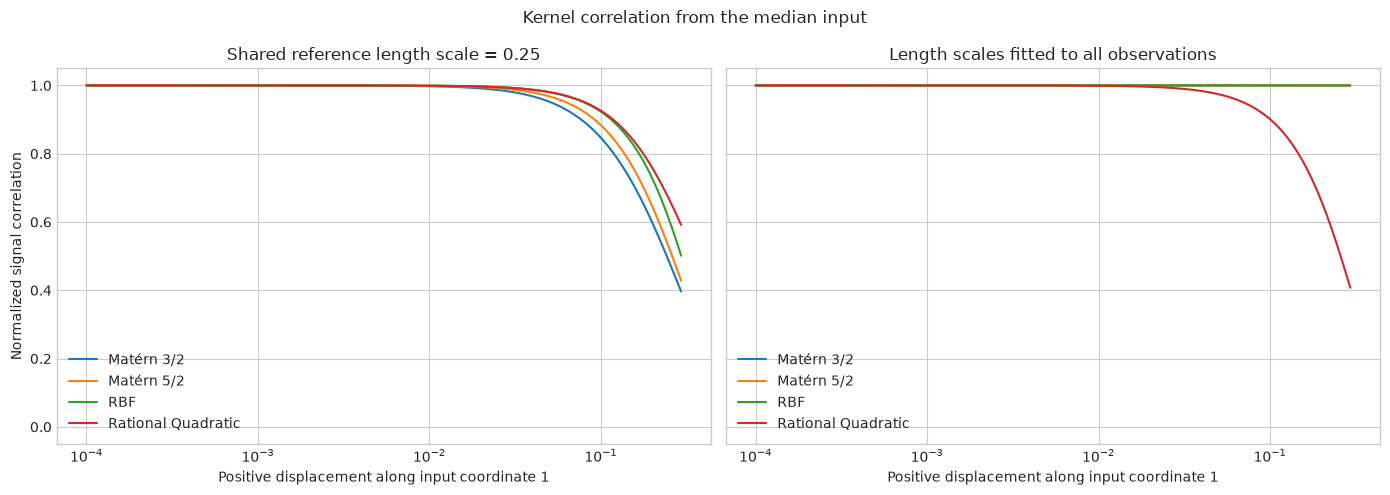

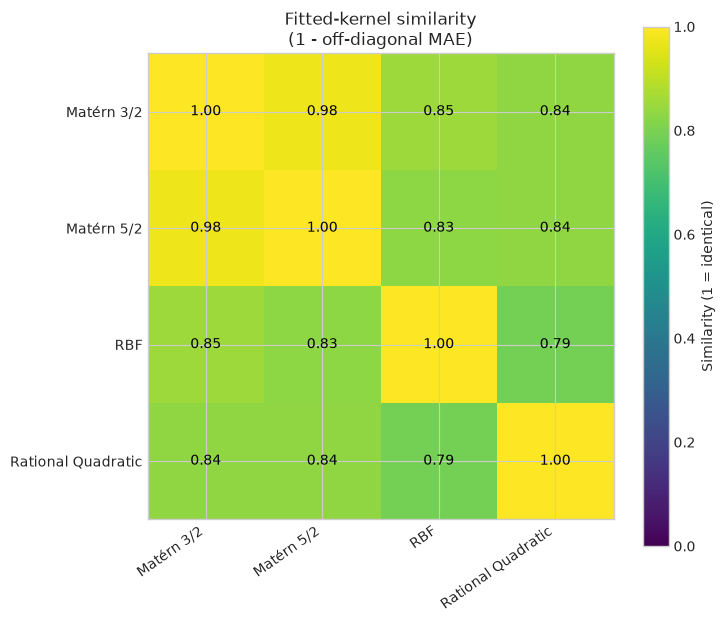

In [5]:
anchor = np.median(X, axis=0)
maximum_displacement = min(anchor[0], np.nextafter(1.0, 0.0) - anchor[0])
displacements = np.logspace(-4, np.log10(maximum_displacement), 250)
query_points = np.repeat(anchor[None, :], len(displacements), axis=0)
query_points[:, 0] += displacements


def normalized_correlation(signal_kernel):
    cross_covariance = signal_kernel(query_points, anchor[None, :]).ravel()
    query_variance = signal_kernel.diag(query_points)
    anchor_variance = signal_kernel.diag(anchor[None, :])[0]
    return cross_covariance / np.sqrt(query_variance * anchor_variance)


def reference_signal_kernel(kernel_name):
    reference_scale = 0.25
    if kernel_name == "Matérn 3/2":
        return Matern(length_scale=np.full(X.shape[1], reference_scale), nu=1.5)
    if kernel_name == "Matérn 5/2":
        return Matern(length_scale=np.full(X.shape[1], reference_scale), nu=2.5)
    if kernel_name == "RBF":
        return RBF(length_scale=np.full(X.shape[1], reference_scale))
    return RationalQuadratic(length_scale=reference_scale, alpha=1.0)


fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for kernel_name, model in full_models.items():
    axes[0].plot(
        displacements,
        normalized_correlation(reference_signal_kernel(kernel_name)),
        label=kernel_name,
    )
    axes[1].plot(
        displacements,
        normalized_correlation(model.kernel_.k1),
        label=kernel_name,
    )

axes[0].set_title("Shared reference length scale = 0.25")
axes[1].set_title("Length scales fitted to all observations")
for ax in axes:
    ax.set_xscale("log")
    ax.set_xlabel("Positive displacement along input coordinate 1")
    ax.set_ylim(-0.05, 1.05)
    ax.legend()
axes[0].set_ylabel("Normalized signal correlation")
fig.suptitle("Kernel correlation from the median input")
fig.tight_layout()
plt.show()

normalized_matrices = {}
for kernel_name, model in full_models.items():
    signal_kernel = model.kernel_.k1
    covariance = signal_kernel(X)
    diagonal = signal_kernel.diag(X)
    normalized_matrices[kernel_name] = covariance / np.sqrt(np.outer(diagonal, diagonal))

off_diagonal_indices = np.triu_indices(len(X), k=1)
kernel_vectors = np.vstack([
    normalized_matrices[name][off_diagonal_indices]
    for name in full_models
])
similarity_values = np.ones((len(full_models), len(full_models)))
for row in range(len(full_models)):
    for column in range(len(full_models)):
        mean_absolute_difference = np.mean(np.abs(kernel_vectors[row] - kernel_vectors[column]))
        similarity_values[row, column] = np.clip(1.0 - mean_absolute_difference, 0.0, 1.0)
similarity = pd.DataFrame(
    similarity_values,
    index=list(full_models),
    columns=list(full_models),
)

fig, ax = plt.subplots(figsize=(7.5, 6.5))
image = ax.imshow(similarity, vmin=0, vmax=1, cmap="viridis")
ax.set_xticks(range(len(similarity.columns)), similarity.columns, rotation=35, ha="right")
ax.set_yticks(range(len(similarity.index)), similarity.index)
ax.set_title("Fitted-kernel similarity\n(1 - off-diagonal MAE)")
for row in range(len(similarity.index)):
    for column in range(len(similarity.columns)):
        score = similarity.iloc[row, column]
        label_color = "black" if score > 0.5 else "white"
        ax.text(column, row, f"{score:.2f}", ha="center", va="center", color=label_color)
fig.colorbar(image, ax=ax, label="Similarity (1 = identical)")
fig.tight_layout()
plt.show()

## 5. Plot 2D posterior slices

Function 3 has three inputs, so each row varies one coordinate pair while fixing the third at its median observed value. Each row shares a color scale across all kernels, preventing per-panel autoscaling from exaggerating tiny numerical variation. The plots show model predictions on each slice, not observed function values away from sampled points. Posterior standard deviation is plotted separately from posterior mean.

x1 vs x2; x3 fixed at 0.306
x1 vs x3; x2 fixed at 0.419
x2 vs x3; x1 fixed at 0.294


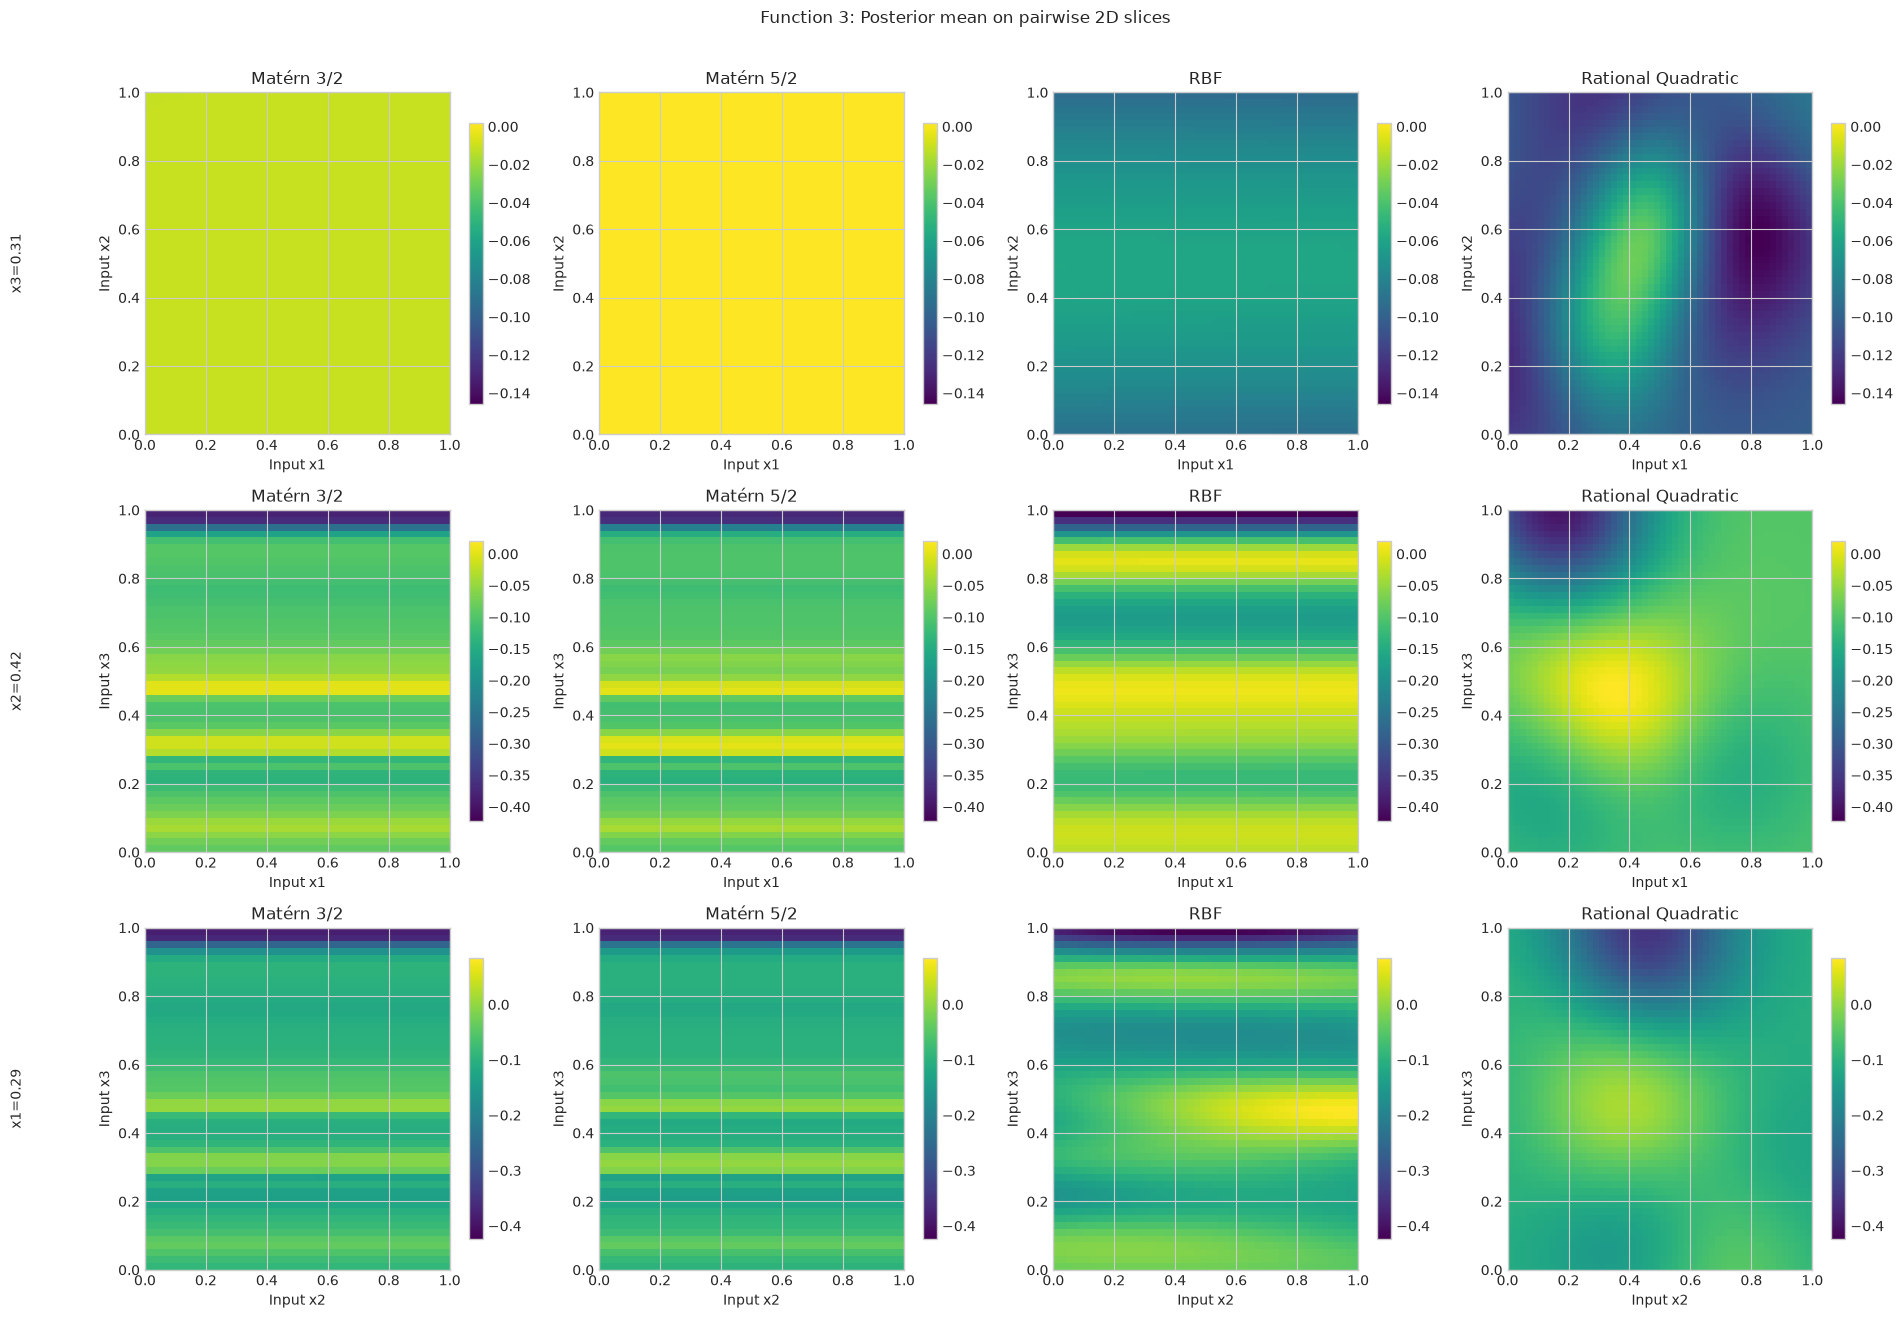

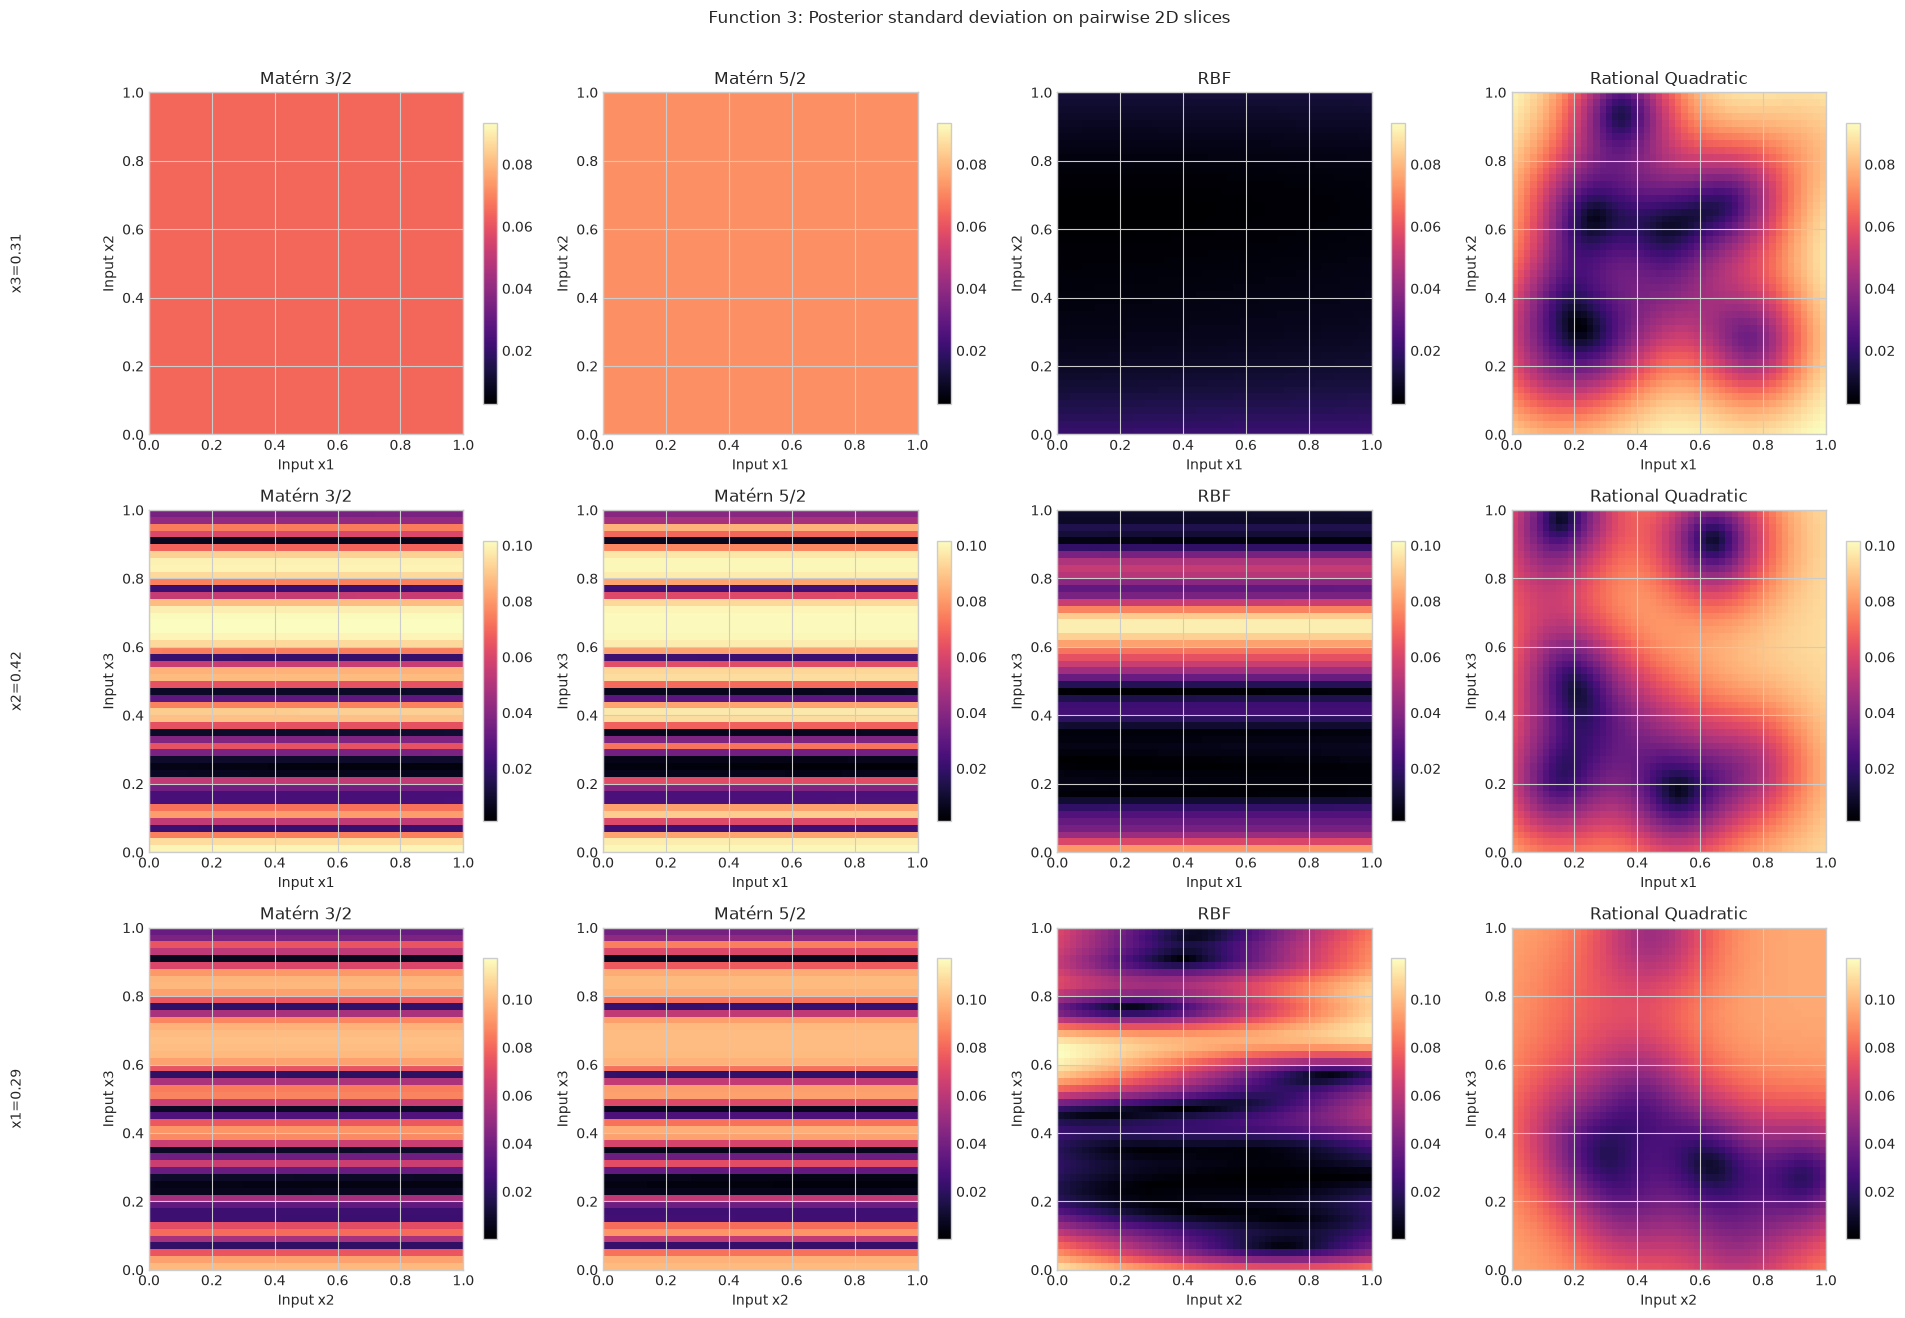

In [6]:
coordinate_pairs = list(combinations(range(X.shape[1]), 2))
grid_axis = np.linspace(0.0, np.nextafter(1.0, 0.0), 50)
mesh_first, mesh_second = np.meshgrid(grid_axis, grid_axis)
slice_predictions = {}

for pair in coordinate_pairs:
    first_coordinate, second_coordinate = pair
    fixed_coordinate = next(index for index in range(X.shape[1]) if index not in pair)
    grid_inputs = np.repeat(anchor[None, :], mesh_first.size, axis=0)
    grid_inputs[:, first_coordinate] = mesh_first.ravel()
    grid_inputs[:, second_coordinate] = mesh_second.ravel()

    for kernel_name, model in full_models.items():
        mean, std = model.predict(grid_inputs, return_std=True)
        slice_predictions[(pair, kernel_name)] = (
            mean.reshape(mesh_first.shape),
            std.reshape(mesh_first.shape),
        )

    print(
        f"x{first_coordinate + 1} vs x{second_coordinate + 1}; "
        f"x{fixed_coordinate + 1} fixed at {anchor[fixed_coordinate]:.3f}"
    )

for quantity_index, quantity_name in enumerate(("Posterior mean", "Posterior standard deviation")):
    figure, axes = plt.subplots(3, 4, figsize=(19, 13), squeeze=False)
    for row, pair in enumerate(coordinate_pairs):
        first_coordinate, second_coordinate = pair
        fixed_coordinate = next(index for index in range(X.shape[1]) if index not in pair)
        row_values = np.stack([
            slice_predictions[(pair, kernel_name)][quantity_index]
            for kernel_name in full_models
        ])
        color_min = float(np.nanmin(row_values))
        color_max = float(np.nanmax(row_values))
        if np.isclose(color_min, color_max):
            padding = max(abs(color_min) * 1e-6, 1e-6)
            color_min -= padding
            color_max += padding

        for column, kernel_name in enumerate(full_models):
            values = slice_predictions[(pair, kernel_name)][quantity_index]
            image = axes[row, column].imshow(
                values,
                origin="lower",
                extent=(grid_axis[0], grid_axis[-1], grid_axis[0], grid_axis[-1]),
                aspect="auto",
                interpolation="nearest",
                vmin=color_min,
                vmax=color_max,
                cmap="viridis" if quantity_index == 0 else "magma",
            )
            axes[row, column].set_title(kernel_name)
            axes[row, column].set_xlabel(f"Input x{first_coordinate + 1}")
            axes[row, column].set_ylabel(f"Input x{second_coordinate + 1}")
            colorbar = figure.colorbar(image, ax=axes[row, column], shrink=0.82)
            colorbar.formatter.set_useOffset(False)
            colorbar.formatter.set_scientific(False)
            colorbar.update_ticks()
        axes[row, 0].text(
            -0.42,
            0.5,
            f"x{fixed_coordinate + 1}={anchor[fixed_coordinate]:.2f}",
            transform=axes[row, 0].transAxes,
            rotation=90,
            va="center",
            ha="center",
        )
    figure.suptitle(f"Function 3: {quantity_name} on pairwise 2D slices", y=1.01)
    figure.tight_layout()
    plt.show()

## 6. Create and visualize shared cross-validation folds

One shuffled five-fold split is created once and reused for every kernel. Each sample appears in one validation fold and in the training set for the other four folds. The fold assignment plot makes the held-out rows visible; kernel hyperparameters are refit using only each fold's training rows.

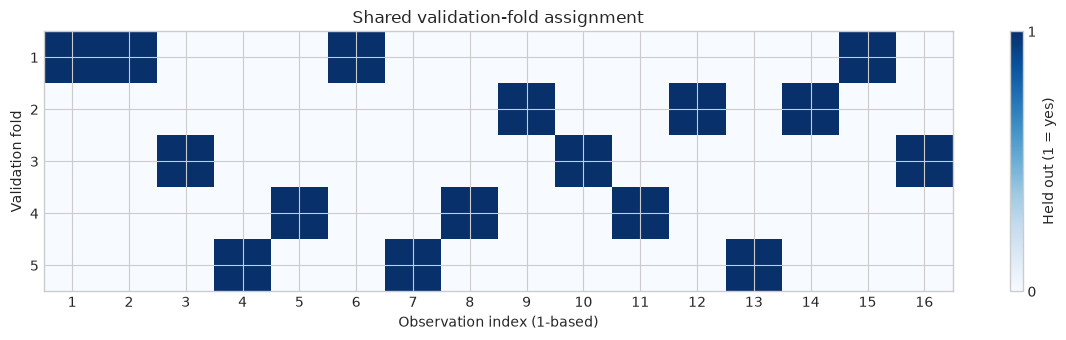

In [7]:
cross_validator = KFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=CONFIG["random_state"],
)
folds = list(cross_validator.split(X))
fold_membership = np.zeros((N_SPLITS, len(X)), dtype=int)

for fold_number, (_, validation_indices) in enumerate(folds):
    fold_membership[fold_number, validation_indices] = 1


fig, ax = plt.subplots(figsize=(12, 3.5))
image = ax.imshow(fold_membership, aspect="auto", interpolation="nearest", cmap="Blues")
ax.set(
    xlabel="Observation index (1-based)",
    ylabel="Validation fold",
    title="Shared validation-fold assignment",
)
ax.set_xticks(np.arange(len(X)), np.arange(1, len(X) + 1))
ax.set_yticks(np.arange(N_SPLITS), np.arange(1, N_SPLITS + 1))
fig.colorbar(image, ax=ax, ticks=[0, 1], label="Held out (1 = yes)")
fig.tight_layout()
plt.show()

In [8]:
fold_table = pd.DataFrame({
    "fold": np.arange(1, N_SPLITS + 1),
    "validation_indices_zero_based": [validation.tolist() for _, validation in folds],
    "training_rows": [len(training) for training, _ in folds],
    "validation_rows": [len(validation) for _, validation in folds],
})
fold_table


,fold,validation_indices_zero_based,training_rows,validation_rows
0,1,"[0, 1, 5, 14]",12,4
1,2,"[8, 11, 13]",13,3
2,3,"[2, 9, 15]",13,3
3,4,"[4, 7, 10]",13,3
4,5,"[3, 6, 12]",13,3


## 7. Score kernels across folds

For each shared fold, fit a fresh GP using only training observations, then score predictions on held-out observations. RMSE and MAE measure point-prediction error. NRMSE divides RMSE by the output standard deviation to make scores easier to compare across differently scaled targets. Gaussian negative log predictive density and 90% interval coverage also test whether predicted uncertainty is informative and reasonably calibrated.

In [ ]:
cv_results = cross_validate_kernels(
    X,
    y,
    kernel_factories,
    n_splits=N_SPLITS,
    random_state=CONFIG["random_state"],
    n_restarts_optimizer=CONFIG["n_restarts_optimizer"],
    normalize_y=CONFIG["normalize_y"],
)
metric_columns = [
    "RMSE",
    "NRMSE",
    "MAE",
    "negative_log_predictive_density",
    "coverage_90",
]
cv_summary = cv_results.groupby("kernel")[metric_columns].agg(["mean", "std"])
cv_summary.columns = [f"{metric}_{statistic}" for metric, statistic in cv_summary.columns]
cv_summary.sort_values("NRMSE_mean", inplace=True)

/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 1 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound and calling fit again may find a better value.
  warnings.warn(
/home/pabloncho/repositories/bayesian-bbo/.venv/lib/python3.14/site-packages/sklearn/gaussian_process/kernels.py:455: ConvergenceWarning: The optimal value found for dimension 0 of parameter k1__k2__length_scale is close to the specified upper bound 31.622776601683793. Increasing the bound

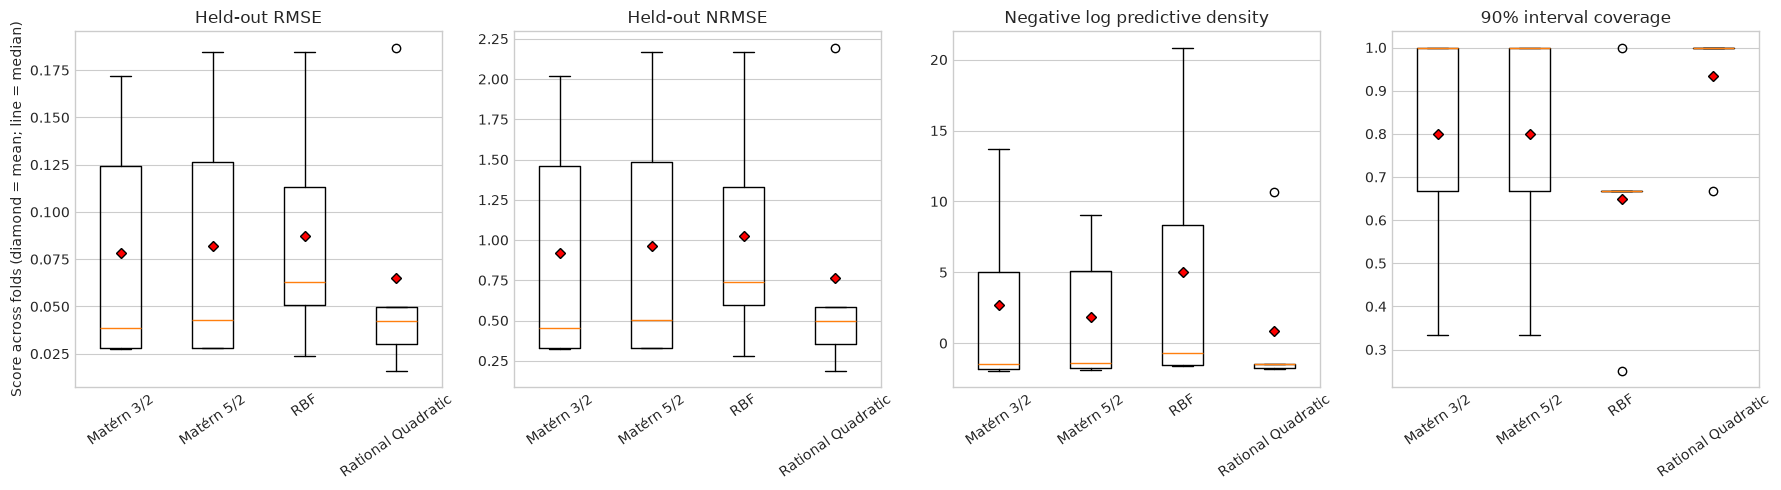

Kernels ranked by mean held-out NRMSE:


,RMSE_mean,RMSE_std,NRMSE_mean,NRMSE_std,MAE_mean,MAE_std,negative_log_predictive_density_mean,negative_log_predictive_density_std,coverage_90_mean,coverage_90_std
kernel,,,,,,,,,,
Rational Quadratic,0.064983,0.069399,0.763201,0.815062,0.053636,0.047598,0.827033,5.491712,0.933333,0.149071
Matérn 3/2,0.078067,0.066385,0.916876,0.779665,0.057175,0.042693,2.695706,6.815554,0.800000,0.298142
Matérn 5/2,0.081936,0.070436,0.962311,0.827248,0.059587,0.044793,1.817504,5.011572,0.800000,0.298142
RBF,0.087022,0.063405,1.022044,0.744665,0.061238,0.039535,5.055918,9.772300,0.650000,0.266145


In [ ]:
metric_specs = [
    ("RMSE", "Held-out RMSE"),
    ("NRMSE", "Held-out NRMSE"),
    ("negative_log_predictive_density", "Negative log predictive density"),
    ("coverage_90", "90% interval coverage"),
]
kernel_names = list(kernel_factories)

fig, axes = plt.subplots(1, len(metric_specs), figsize=(18, 5))
for ax, (metric, title) in zip(axes, metric_specs):
    values = [cv_results.loc[cv_results["kernel"] == name, metric] for name in kernel_names]
    ax.boxplot(
        values,
        tick_labels=kernel_names,
        showmeans=True,
        meanprops={
            "marker": "D",
            "markerfacecolor": "red",
            "markeredgecolor": "black",
            "markersize": 5,
        },
    )
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="x", visible=False)
axes[0].set_ylabel("Score across folds (diamond = mean; line = median)")
fig.tight_layout()
plt.show()

print("Kernels ranked by mean held-out NRMSE:")
cv_summary.sort_values("NRMSE_mean")

## Interpreting the comparison

Kernels are ranked by mean held-out NRMSE. RMSE and MAE are reported alongside it. Lower values indicate better point predictions on these sampled inputs. Negative log predictive density evaluates both predictions and uncertainty; 90% coverage near `0.90` is a rough calibration target, though the validation sets contain only three or four observations each.

With the current 16 Function 3 observations, Rational Quadratic has the lowest mean held-out RMSE, MAE, and NRMSE in this run, but fold-to-fold variation is large. Some Matérn and RBF length scales reach the configured upper bound (`LENGTH_CAP`, currently `31.62`), and Rational Quadratic's alpha reaches its upper bound (`1e5`). These boundary warnings indicate constrained hyperparameter estimates, not failed fits. The evidence does not identify a definitive winning kernel.

Cross-validation assesses predictions at held-out sampled inputs, not global optimization performance or guaranteed interpolation. Re-run the notebook as new observations are added; with this small dataset, kernel rankings and fitted hyperparameters may change.

## Kernel choice for Notebook 06

Rational Quadratic is not a submission candidate. Notebook 06 uses Matérn 3/2 for Function 3, as for every function, based on the cross-function comparison in Notebook 04. This single-function comparison does not change that choice.